# Episode 5: Derivatives and the Chain Rule
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2005%20-%20Derivatives%20and%20the%20Chain%20Rule/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*. Calculus for Learning, part 1 of 2.

The episode works every calculation by hand. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. It uses only `numpy` and `matplotlib` (both already in Colab): choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | The derivative: a slope the slow way, the power rule proved by hand, and the rules | 7, 6.1, 6.01 → 6 · 2z + Δ |
| 2 | The slope of surprisal and a nudge check | −3.33 · 1.137 vs 1.139 |
| 3 | The calculus chain rule: a tiny example, then through softmax, with the quotient rule worked out | 18 · −3.33 · 0.21 · −0.70 |
| 4 | Testing the slope: a small nudge and a big step | 0.069 · 0.584 |
| 5 | The check question | −2 · 0.25 · −0.50 |
| 6 | Try it yourself, with self-checks | 19, 12.61, 12.0601 → 12 · your numbers |

Episode 1's four-word probabilities (mat 0.30, floor 0.20, sofa 0.15, other 0.35, after “The cat sat on the”) are **illustrative**, and Episode 4's surprisal for mat, −ln 0.30 = 1.204 nats, is where this episode starts. Logs are natural (nats).

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

STEEL, GOLD, CORAL, MUTED = "#8FB4E8", "#FFC400", "#FF4D3D", "#8B98AE"   # the video's colours


def fmt(x):
    """Print a number the way you would write it on paper: 9.0601, not 9.060099999999998."""
    return f"{round(float(x), 8):.10g}"


def surprisal(x):
    """-ln p, in nats (Episode 4)."""
    return -np.log(x)


def slope_numeric(f, z, h=1e-6):
    """Central difference: the slope of f at z, measured with a tiny step on each side."""
    return (f(z + h) - f(z - h)) / (2 * h)

## Part 1 · The derivative

**The speedometer.** A speedometer reading 60 mph does not mean you will drive 60 miles. It means that right now, at this instant, your distance is growing at 60 miles per hour: a rate of change at one moment. A derivative is the same idea: how fast the output changes, per unit of input, at one point. For a car, miles per hour. For a model, how much surprisal changes per unit change in a score.

The derivative f′(z) is the slope of f at z. It gives a prediction, the **small-change rule**:

f(z + Δ) ≈ f(z) + Δ · f′(z)

### Step 1: a slope by hand, the slow way
Take f(z) = z² at z = 3. Step away by Δ, see how much f changes, and divide by the step. `slope_by_hand` prints the worksheet the video shows.

In [2]:
def slope_by_hand(f, z, steps):
    """Secant slopes (f(z + step) - f(z)) / step, printed line by line."""
    fz = f(z)
    print(f"f({fmt(z)}) = {fmt(fz)}")
    slopes = []
    for d in steps:
        fd = f(z + d)
        change = fd - fz
        slope = change / d
        a = f"f({fmt(z + d)}) = {fmt(fd)}"
        b = f"change {fmt(fd)} - {fmt(fz)} = {fmt(change)}"
        print(f"step {fmt(d):5s} {a:20s} {b:30s} slope {fmt(change)} / {fmt(d)} = {fmt(slope)}")
        slopes.append(slope)
    return np.array(slopes)


def square(z):
    return z ** 2


secants = slope_by_hand(square, 3, [1, 0.1, 0.01])
print("\n7, 6.1, 6.01: the slopes are closing in on 6")
assert square(3) == 9 and square(4) == 16
assert round(square(3.1), 6) == 9.61 and round(square(3.01), 6) == 9.0601
assert np.allclose(np.round(secants, 6), [7, 6.1, 6.01])

f(3) = 9
step 1     f(4) = 16            change 16 - 9 = 7              slope 7 / 1 = 7
step 0.1   f(3.1) = 9.61        change 9.61 - 9 = 0.61         slope 0.61 / 0.1 = 6.1
step 0.01  f(3.01) = 9.0601     change 9.0601 - 9 = 0.0601     slope 0.0601 / 0.01 = 6.01

7, 6.1, 6.01: the slopes are closing in on 6


### Step 2: prove the power rule by hand
Why is the slope of z² exactly 2z? Three lines:

1. Step from z to z + Δ: (z + Δ)² = z² + 2zΔ + Δ²
2. Subtract the old value z²: the change is 2zΔ + Δ²
3. Divide by the step Δ: **2z + Δ**

Let the step shrink toward zero and the Δ on the end disappears: the slope is 2z, and at z = 3 that is 6. The cell checks each line with numbers, then lines the formula 2z + Δ up against the table above.

In [3]:
for z_, d_ in [(3, 1), (3, 0.1), (-2, 0.5), (1.7, 0.03)]:          # line 1: the expansion, at a few points
    assert np.isclose((z_ + d_) ** 2, z_ ** 2 + 2 * z_ * d_ + d_ ** 2)

z = 3
print("((z + Δ)² - z²) / Δ  =  2z + Δ,  at z = 3")
for d in [1, 0.1, 0.01, 0.001]:
    measured = ((z + d) ** 2 - z ** 2) / d
    formula = 2 * z + d
    left = f"((3 + {fmt(d)})² - 9) / {fmt(d)} = {fmt(measured)}"
    print(f"  step {fmt(d):6s} {left:38s} 2 x 3 + {fmt(d)} = {fmt(formula)}")
    assert np.isclose(measured, formula)
print("\nthe table again: 7 = 6 + 1,  6.1 = 6 + 0.1,  6.01 = 6 + 0.01  (the extra bit was always the step)")
assert np.allclose(secants, 2 * 3 + np.array([1, 0.1, 0.01]))
print(f"step -> 0: 2z = 2 x 3 = {2 * 3}")
assert np.isclose(slope_numeric(square, 3), 6)

((z + Δ)² - z²) / Δ  =  2z + Δ,  at z = 3
  step 1      ((3 + 1)² - 9) / 1 = 7                 2 x 3 + 1 = 7
  step 0.1    ((3 + 0.1)² - 9) / 0.1 = 6.1           2 x 3 + 0.1 = 6.1
  step 0.01   ((3 + 0.01)² - 9) / 0.01 = 6.01        2 x 3 + 0.01 = 6.01
  step 0.001  ((3 + 0.001)² - 9) / 0.001 = 6.001     2 x 3 + 0.001 = 6.001

the table again: 7 = 6 + 1,  6.1 = 6 + 0.1,  6.01 = 6 + 0.01  (the extra bit was always the step)
step -> 0: 2z = 2 x 3 = 6


### Step 3: the rules
You don't have to do that every time. The **power rule**: d/dz z² = 2z (more generally, d/dz zⁿ = n zⁿ⁻¹), so at 3 the slope is 6, exactly where the secants were heading. And the one we need for surprisal: **d/dz ln z = 1/z**. The cell checks both against measured slopes, and the plot shows the secant lines closing in on the tangent.

power rule: d/dz z^2 = 2z  ->  2 x 3 = 6
d/dz ln z = 1/z: checked at z = 0.5, 1, 2, 3


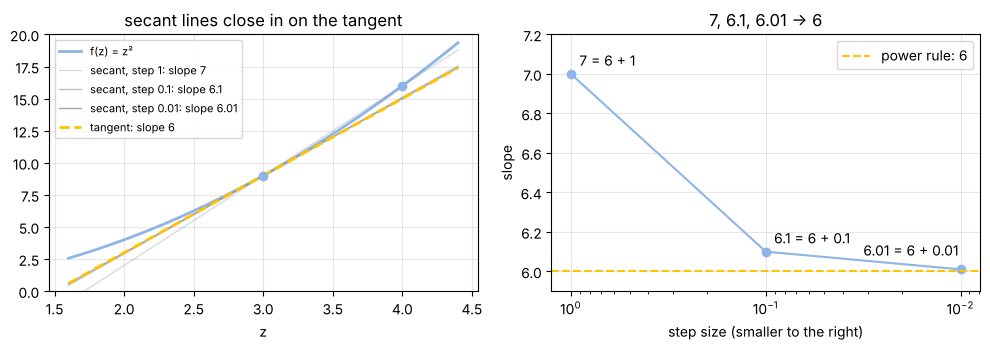

In [4]:
print(f"power rule: d/dz z^2 = 2z  ->  2 x 3 = {2 * 3}")
for z_ in [0.5, 1, 2, 3]:
    assert np.isclose(slope_numeric(np.log, z_), 1 / z_)               # d/dz ln z = 1/z
    assert np.isclose(slope_numeric(square, z_), 2 * z_)               # d/dz z^2 = 2z
print("d/dz ln z = 1/z: checked at z = 0.5, 1, 2, 3")

zz = np.linspace(1.6, 4.4, 200)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(zz, square(zz), color=STEEL, lw=2, label="f(z) = z²")
for d, s, a in zip([1, 0.1, 0.01], secants, [0.35, 0.6, 0.85]):
    ax[0].plot(zz, 9 + s * (zz - 3), color=MUTED, lw=1, alpha=a, label=f"secant, step {d}: slope {fmt(s)}")
ax[0].plot(zz, 9 + 6 * (zz - 3), color=GOLD, lw=2, ls="--", label="tangent: slope 6")
ax[0].plot([3, 4], [9, 16], "o", color=STEEL)
ax[0].set_ylim(0, 20); ax[0].set_xlabel("z"); ax[0].set_title("secant lines close in on the tangent")
ax[0].legend(fontsize=8)
ax[1].semilogx([1, 0.1, 0.01], secants, "o-", color=STEEL)
ax[1].axhline(6, color=GOLD, ls="--", label="power rule: 6")
for d, s, off in zip([1, 0.1, 0.01], secants, [(6, 6), (6, 6), (-70, 10)]):
    ax[1].annotate(f"{fmt(s)} = 6 + {fmt(d)}", (d, s), textcoords="offset points", xytext=off)
ax[1].set_ylim(5.9, 7.2); ax[1].invert_xaxis(); ax[1].set_xlabel("step size (smaller to the right)"); ax[1].set_ylabel("slope")
ax[1].set_title("7, 6.1, 6.01 → 6"); ax[1].legend()
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Part 2 · The slope of surprisal

### Step 4: −ln p as a curve
Surprisal is S(p) = −ln p. Since d/dz ln z = 1/z, its slope is −1/p. At p = 0.30 that is −1 ÷ 0.30 = −3.33: raise mat's probability a little and surprisal falls about 3.33 times as fast.

In [5]:
S0 = surprisal(0.30)
dS = -1 / 0.30
print(f"S(0.30) = -ln 0.30 = {S0:.3f} nats   (Episode 4)")
print(f"slope: -1 / p = -1 / 0.30 = {dS:.2f}   (measured: {slope_numeric(surprisal, 0.30):.2f})")
assert round(S0, 3) == 1.204 and round(dS, 2) == -3.33
assert np.isclose(slope_numeric(surprisal, 0.30), dS)

S(0.30) = -ln 0.30 = 1.204 nats   (Episode 4)
slope: -1 / p = -1 / 0.30 = -3.33   (measured: -3.33)


### Step 5: check the prediction
Move p from 0.30 to 0.32, a nudge of Δ = 0.02. Predict with the small-change rule, then compute the true value.

In [6]:
estimate = 1.204 - 0.02 * 3.33               # the video's rounded numbers
true = surprisal(0.32)
print(f"prediction: 1.204 - 0.02 x 3.33 = 1.204 - {0.02 * 3.33:.4f} = {estimate:.3f}")
print(f"true value: -ln 0.32 = {true:.3f}")
print(f"off by {true - estimate:.3f}: for a small nudge, the slope is a very good guide")
assert round(estimate, 3) == 1.137 and round(S0 + 0.02 * dS, 3) == 1.137   # same with unrounded numbers
assert round(true, 3) == 1.139 and round(true - estimate, 3) == 0.002

prediction: 1.204 - 0.02 x 3.33 = 1.204 - 0.0666 = 1.137
true value: -ln 0.32 = 1.139
off by 0.002: for a small nudge, the slope is a very good guide


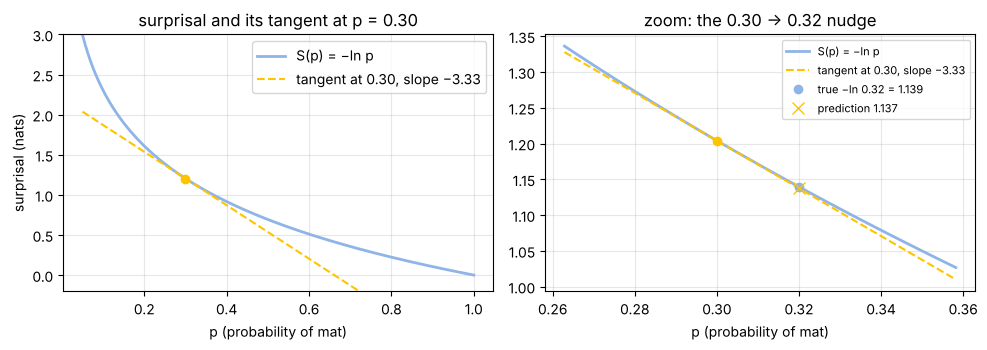

In [7]:
pp = np.linspace(0.05, 1, 300)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, (lo, hi) in zip(ax, [(0.05, 1), (0.26, 0.36)]):
    m = (pp >= lo) & (pp <= hi)
    a.plot(pp[m], surprisal(pp[m]), color=STEEL, lw=2, label="S(p) = −ln p")
    a.plot(pp[m], S0 + dS * (pp[m] - 0.30), color=GOLD, ls="--", lw=1.5, label="tangent at 0.30, slope −3.33")
    a.plot(0.30, S0, "o", color=GOLD)
    a.set_xlabel("p (probability of mat)")
    a.grid(alpha=0.3)
ax[0].set_ylim(-0.2, 3); ax[0].set_ylabel("surprisal (nats)"); ax[0].set_title("surprisal and its tangent at p = 0.30")
ax[0].legend()
ax[1].plot(0.32, true, "o", color=STEEL, label=f"true −ln 0.32 = {true:.3f}")
ax[1].plot(0.32, estimate, "x", color=GOLD, ms=9, label=f"prediction {estimate:.3f}")
ax[1].set_title("zoom: the 0.30 → 0.32 nudge"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Part 3 · The calculus chain rule

Most real functions are chains: first g acts on z, then f acts on the result.

d/dz f(g(z)) = f′(g(z)) · g′(z)

Read it as cause and effect: nudge z and g moves by g′ times the nudge; that move in g moves f by f′ times itself. Multiply the two effects. (This is **not** Episode 4's chain rule of probability, which multiplies conditional probabilities. Same name, different rule.)

### Step 6: a tiny example
g(z) = 3z and f(u) = u², at z = 1. `chain_by_hand` prints both links, multiplies them, and then checks the answer by measuring the slope of the whole chain directly.

In [8]:
def chain_by_hand(f, df, g, dg, z, digits=2):
    """Chain rule, link by link, then a direct check on f(g(z))."""
    u = g(z)
    inner, outer = dg(z), df(u)
    total = outer * inner
    print(f"inner link: g({fmt(round(z, 3))}) = {u:.{digits}f},  g'(z) = {inner:.{digits}f}")
    print(f"outer link: f'(g(z)) = f'({u:.{digits}f}) = {outer:.{digits}f}")
    print(f"chain rule: {outer:.{digits}f} x {inner:.{digits}f} = {total:.{digits}f}")
    direct = slope_numeric(lambda t: f(g(t)), z)
    print(f"check, slope of f(g(z)) measured directly: {direct:.{digits}f}")
    assert np.isclose(direct, total, atol=1e-5)
    return total


tiny = chain_by_hand(f=lambda u: u ** 2, df=lambda u: 2 * u, g=lambda z: 3 * z, dg=lambda z: 3, z=1, digits=0)
print("the long way: f(g(z)) = (3z)^2 = 9z^2, derivative 18z, at z = 1:", 18 * 1)
assert tiny == 18 and 6 * 3 == 18

inner link: g(1) = 3,  g'(z) = 3
outer link: f'(g(z)) = f'(3) = 6
chain rule: 6 x 3 = 18
check, slope of f(g(z)) measured directly: 18
the long way: f(g(z)) = (3z)^2 = 9z^2, derivative 18z, at z = 1: 18


### Step 7: the chain through softmax
In Episode 4, softmax turned scores into probabilities. Let z be the score for mat. Hold the other three scores fixed and lump their weights into one number, R = 0.20 + 0.15 + 0.35 = 0.70. Then

- the probability of mat is g(z) = eᶻ ÷ (eᶻ + R),
- surprisal is f(p) = −ln p.

Two links: **score z → probability p → surprisal S**. Start at z = ln 0.30, which gives exactly p = 0.30, Episode 4's number.

In [9]:
R = 0.20 + 0.15 + 0.35
z0 = np.log(0.30)


def p_of_z(z):
    """mat's softmax probability when the other words' weight is lumped into R."""
    return np.exp(z) / (np.exp(z) + R)


def S_of_z(z):
    """mat's surprisal as a function of mat's score."""
    return surprisal(p_of_z(z))


p0 = p_of_z(z0)
print(f"R = 0.20 + 0.15 + 0.35 = {R:.2f}")
print(f"z = ln 0.30 = {z0:.3f}")
print(f"g(z) = e^z / (e^z + R) = {np.exp(z0):.2f} / ({np.exp(z0):.2f} + {R:.2f}) = {p0:.2f}")
assert round(R, 2) == 0.70 and np.isclose(p0, 0.30)
h = np.log([0.30, 0.20, 0.15, 0.35])          # the same thing as a full four-word softmax
assert np.isclose(np.exp(h[0]) / np.exp(h).sum(), p0)

R = 0.20 + 0.15 + 0.35 = 0.70
z = ln 0.30 = -1.204
g(z) = e^z / (e^z + R) = 0.30 / (0.30 + 0.70) = 0.30


**Math Lab.** The outer link is f′(p) = −1/p. The inner link, the slope of the softmax probability, comes out beautifully simple: g′(z) = p(1 − p). Every bit of the score's nudge that reaches mat's probability gets scaled by it.

In [10]:
print("Math Lab")
print(f"outer link: f'(p) = -1/p = -1/{p0:.2f} = {-1 / p0:.2f}")
print(f"inner link: g'(z) = p(1 - p) = {p0:.2f} x {1 - p0:.2f} = {p0 * (1 - p0):.2f}")
assert round(-1 / p0, 2) == -3.33 and round(p0 * (1 - p0), 2) == 0.21

Math Lab
outer link: f'(p) = -1/p = -1/0.30 = -3.33
inner link: g'(z) = p(1 - p) = 0.30 x 0.70 = 0.21


### Step 8: where p(1 − p) comes from, the quotient rule
p is a fraction: **top** = eᶻ, **bottom** = eᶻ + R. The quotient rule:

(top ÷ bottom)′ = (top′ · bottom − top · bottom′) ÷ bottom²

Two slopes are needed. The slope of eᶻ is eᶻ itself (that's what makes e special). R doesn't change, so bottom′ = eᶻ too. Plug in:

g′(z) = [eᶻ(eᶻ + R) − eᶻ · eᶻ] ÷ (eᶻ + R)²

Both products contain eᶻ · eᶻ, and it cancels. What's left on top is R · eᶻ:

**g′(z) = R · eᶻ ÷ (eᶻ + R)²**

Then rewrite it: eᶻ ÷ bottom is just p, and R ÷ bottom is 1 − p, so g′(z) = p(1 − p). Same answer, two ways. The cell does the numbers at our starting point, then checks the formula against measured slopes and against p(1 − p) at many scores.

In [11]:
def g_prime_quotient(z):
    """The quotient rule exactly as written, before anything cancels."""
    top, bottom = np.exp(z), np.exp(z) + R
    d_top, d_bottom = np.exp(z), np.exp(z)        # (e^z)' = e^z; R is fixed, so (e^z + R)' = e^z
    return (d_top * bottom - top * d_bottom) / bottom ** 2


def g_prime(z):
    """After e^z * e^z cancels: R e^z / (e^z + R)^2."""
    return R * np.exp(z) / (np.exp(z) + R) ** 2


ez = np.exp(z0)
bottom = ez + R
print(f"at z = ln 0.30:  e^z = {ez:.2f},  bottom = {ez:.2f} + {R:.2f} = {bottom:.0f}")
print(f"g'(z) = R e^z / (e^z + R)^2 = {R:.2f} × {ez:.2f} ÷ {bottom:.0f}² = {g_prime(z0):.2f}")
print(f"rewrite: e^z / bottom = p = {ez / bottom:.2f},  R / bottom = 1 - p = {R / bottom:.2f}")
print(f"g'(z) = p(1 - p) = {p0:.2f} × {1 - p0:.2f} = {p0 * (1 - p0):.2f}   (same answer, two ways)")
assert np.isclose(ez, 0.30) and np.isclose(bottom, 1)
assert round(g_prime(z0), 2) == 0.21 and np.isclose(g_prime(z0), p0 * (1 - p0))

print("\nby numbers, at many scores:")
print("     z   quotient rule   R e^z/(e^z+R)^2   p(1 - p)   measured slope")
for z_ in [-3, -1, z0, 0, 1, 3]:
    pz = p_of_z(z_)
    print(f"{z_:+6.3f}   {g_prime_quotient(z_):13.6f}   {g_prime(z_):15.6f}   {pz * (1 - pz):8.6f}   {slope_numeric(p_of_z, z_):14.6f}")
zs = np.linspace(-6, 6, 241)
assert np.allclose(g_prime_quotient(zs), g_prime(zs))                       # the cancellation
assert np.allclose(g_prime(zs), p_of_z(zs) * (1 - p_of_z(zs)))              # = p(1 - p)
assert np.allclose(g_prime(zs), [slope_numeric(p_of_z, z_) for z_ in zs], atol=1e-8)   # finite differences

at z = ln 0.30:  e^z = 0.30,  bottom = 0.30 + 0.70 = 1
g'(z) = R e^z / (e^z + R)^2 = 0.70 × 0.30 ÷ 1² = 0.21
rewrite: e^z / bottom = p = 0.30,  R / bottom = 1 - p = 0.70
g'(z) = p(1 - p) = 0.30 × 0.70 = 0.21   (same answer, two ways)

by numbers, at many scores:
     z   quotient rule   R e^z/(e^z+R)^2   p(1 - p)   measured slope
-3.000        0.061992          0.061992   0.061992         0.061992
-1.000        0.225818          0.225818   0.225818         0.225818
-1.204        0.210000          0.210000   0.210000         0.210000
+0.000        0.242215          0.242215   0.242215         0.242215
+1.000        0.162846          0.162846   0.162846         0.162846
+3.000        0.032543          0.032543   0.032543         0.032543


### Step 9: multiply the links
(−1 ÷ 0.30) × 0.21 = −(0.21 ÷ 0.30) = −0.70: the derivative of mat's surprisal with respect to mat's score. The shortcut hiding inside: (1/p) · p(1 − p) = 1 − p, so dS/dz = −(1 − p). Raise mat's score, and its surprisal drops at seven tenths of the rate.

In [12]:
print(f"multiply:   (-1/{p0:.2f}) x {p0 * (1 - p0):.2f} = -({p0 * (1 - p0):.2f} / {p0:.2f}) = {-(p0 * (1 - p0)) / p0:.2f}")
print(f"shortcut:   -(1 - p) = -(1 - {p0:.2f}) = {-(1 - p0):.2f}\n")
dSdz = chain_by_hand(f=surprisal, df=lambda u: -1 / u, g=p_of_z, dg=g_prime, z=z0)
assert np.isclose(dSdz, -0.70) and np.isclose(-(1 - p0), -0.70)
assert np.isclose(slope_numeric(S_of_z, z0), -0.70)     # finite-difference check of the whole chain

multiply:   (-1/0.30) x 0.21 = -(0.21 / 0.30) = -0.70
shortcut:   -(1 - p) = -(1 - 0.30) = -0.70

inner link: g(-1.204) = 0.30,  g'(z) = 0.21
outer link: f'(g(z)) = f'(0.30) = -3.33
chain rule: -3.33 x 0.21 = -0.70
check, slope of f(g(z)) measured directly: -0.70


## Part 4 · Testing the slope: a small nudge and a big step
The slope says: raise the score by Δ and surprisal falls by about 0.70 × Δ. `nudge_by_hand` compares that straight-line prediction with what really happens.

In [13]:
def nudge_by_hand(dz):
    pred = -dSdz * dz
    p1, S1 = p_of_z(z0 + dz), S_of_z(z0 + dz)
    actual = S_of_z(z0) - S1
    print(f"raise the score by {dz}: predicted drop {dz} x 0.70 = {pred:.3f}")
    print(f"  p: {p0:.3f} -> {p1:.3f}   S: {S_of_z(z0):.3f} -> {S1:.3f}   actual drop {actual:.3f}   off by {pred - actual:.3f}")
    return p1, S1, actual


p_a, S_a, drop_a = nudge_by_hand(0.1)
p_b, S_b, drop_b = nudge_by_hand(1.0)
assert round(p_a, 3) == 0.321 and round(S_a, 3) == 1.135 and round(drop_a, 3) == 0.069
assert round(-dSdz * 0.1, 3) == 0.070 and round(-dSdz * 0.1 - drop_a, 3) == 0.001
assert round(p_b, 3) == 0.538 and round(S_b, 3) == 0.620 and round(drop_b, 3) == 0.584
print("\nThe slope is a local fact: step far, and the curve bends away from it.")

raise the score by 0.1: predicted drop 0.1 x 0.70 = 0.070
  p: 0.300 -> 0.321   S: 1.204 -> 1.135   actual drop 0.069   off by 0.001
raise the score by 1.0: predicted drop 1.0 x 0.70 = 0.700
  p: 0.300 -> 0.538   S: 1.204 -> 0.620   actual drop 0.584   off by 0.116

The slope is a local fact: step far, and the curve bends away from it.


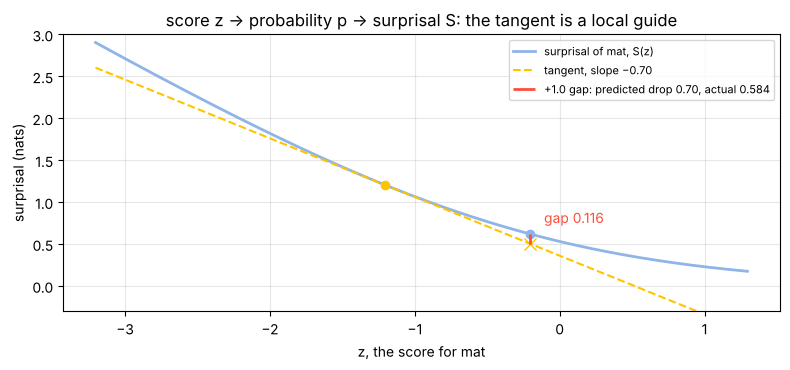

In [14]:
zs = np.linspace(z0 - 2, z0 + 2.5, 300)
plt.figure(figsize=(8, 3.8))
plt.plot(zs, S_of_z(zs), color=STEEL, lw=2, label="surprisal of mat, S(z)")
plt.plot(zs, S_of_z(z0) + dSdz * (zs - z0), color=GOLD, ls="--", lw=1.5, label="tangent, slope −0.70")
plt.plot(z0, S_of_z(z0), "o", color=GOLD)
z1 = z0 + 1.0
plt.plot(z1, S_b, "o", color=STEEL)
plt.plot(z1, S_of_z(z0) - 0.70, "x", color=GOLD, ms=9)
plt.vlines(z1, S_of_z(z0) - 0.70, S_b, color=CORAL, lw=2, label=f"+1.0 gap: predicted drop 0.70, actual {drop_b:.3f}")
plt.annotate(f"gap {0.70 - drop_b:.3f}", (z1, S_b), textcoords="offset points", xytext=(10, 8), color=CORAL)
plt.xlabel("z, the score for mat"); plt.ylabel("surprisal (nats)")
plt.title("score z → probability p → surprisal S: the tangent is a local guide")
plt.ylim(-0.3, 3); plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Part 5 · Check question
Suppose mat's probability were 0.50 instead of 0.30. (a) What is the slope of surprisal with respect to p? (b) What is the inner link, p(1 − p)? (c) What is the slope of surprisal with respect to mat's score?

With R = 0.70 still held fixed, p = 0.50 means eᶻ = R, so z = ln 0.70. The cell answers by hand, then measures the slope of the real chain there.

In [15]:
q = 0.50
outer_q, inner_q = -1 / q, q * (1 - q)
total_q = outer_q * inner_q
zq = np.log(R)
print(f"(a) outer link: -1 / {q:.2f} = {outer_q:.0f}")
print(f"(b) inner link: {q:.2f} x {1 - q:.2f} = {inner_q:.2f}")
print(f"(c) multiply: {outer_q:.0f} x {inner_q:.2f} = {total_q:.2f};  shortcut -(1 - p) = {-(1 - q):.2f}")
print(f"    measured on the real chain at z = ln 0.70 (p = {p_of_z(zq):.2f}): {slope_numeric(S_of_z, zq):.2f}")
assert outer_q == -2 and inner_q == 0.25 and total_q == -0.50 and -(1 - q) == -0.50
assert np.isclose(p_of_z(zq), 0.50) and np.isclose(g_prime(zq), 0.25) and np.isclose(slope_numeric(S_of_z, zq), -0.50)

(a) outer link: -1 / 0.50 = -2
(b) inner link: 0.50 x 0.50 = 0.25
(c) multiply: -2 x 0.25 = -0.50;  shortcut -(1 - p) = -0.50
    measured on the real chain at z = ln 0.70 (p = 0.50): -0.50


## Part 6 · Try it yourself
Change the values in the next cells and re-run them. The self-checks tell you whether your own hand calculation matches.

1. Find the slope of z³ at 2 the slow way, with steps 1, 0.1 and 0.01. Then prove the rule the way we did for z²: expand (z + Δ)³, subtract z³, divide by Δ, and let Δ shrink. Type your answer into `my_answer`.
2. Nudge mat's score by 0.1 and confirm the drop of about 0.07. Try other nudges.
3. Redo the quotient rule with p = 0.50, all on paper, and type your inner link into `my_inner`.

<details><summary>Hint for 1: prove 3z²</summary>

(z + Δ)³ = z³ + 3z²Δ + 3zΔ² + Δ³. Subtract z³ and divide by Δ: 3z² + 3zΔ + Δ². Let Δ → 0: **3z²**. At z = 2 the secant is 12 + 6Δ + Δ², so the extra bits for steps 1, 0.1 and 0.01 are 7, 0.61 and 0.0601.

</details>

In [16]:
my_power, my_z = 3, 2                  # 1. f(z) = z^my_power at z = my_z
my_answer = None                       #    your slope, e.g. 12


def my_f(z):
    return z ** my_power


my_slopes = slope_by_hand(my_f, my_z, [1, 0.1, 0.01])
exact = my_power * my_z ** (my_power - 1)
print(f"power rule: {my_power} x {my_z}^{my_power - 1} = {exact}")
if my_answer is not None:
    print("your answer matches" if np.isclose(my_answer, exact) else f"not quite: the power rule gives {exact}")
assert abs(my_slopes[-1] - exact) < abs(my_slopes[0] - exact)          # smaller steps close in
if (my_power, my_z) == (3, 2):
    assert np.allclose(np.round(my_slopes, 6), [19, 12.61, 12.0601]) and exact == 12
    steps = np.array([1, 0.1, 0.01])
    assert np.allclose(my_slopes, 3 * 2 ** 2 + 3 * 2 * steps + steps ** 2)   # 3z^2 + 3z D + D^2

f(2) = 8
step 1     f(3) = 27            change 27 - 8 = 19             slope 19 / 1 = 19
step 0.1   f(2.1) = 9.261       change 9.261 - 8 = 1.261       slope 1.261 / 0.1 = 12.61
step 0.01  f(2.01) = 8.120601   change 8.120601 - 8 = 0.120601 slope 0.120601 / 0.01 = 12.0601
power rule: 3 x 2^2 = 12


In [17]:
my_dz = 0.1                            # 2. your nudge to mat's score
_, _, my_drop = nudge_by_hand(my_dz)
if my_dz == 0.1:
    assert round(my_drop, 2) == 0.07

raise the score by 0.1: predicted drop 0.1 x 0.70 = 0.070
  p: 0.300 -> 0.321   S: 1.204 -> 1.135   actual drop 0.069   off by 0.001


For 3, R = 0.70 stays fixed, so p = 0.50 needs eᶻ = 0.70 and the bottom is 0.70 + 0.70 = 1.40. (Only the ratio of eᶻ to R matters, so on paper you can also scale both so the bottom is 1: eᶻ = 0.50, R = 0.50. Same answer.)

In [18]:
my_p = 0.50                            # 3. mat's probability
my_inner = None                        #    your g'(z), worked on paper

ez_p = R * my_p / (1 - my_p)           # the e^z that gives p = my_p with R fixed
bot_p = ez_p + R
inner_p = R * ez_p / bot_p ** 2
print(f"e^z = {ez_p:.2f},  bottom = {ez_p:.2f} + {R:.2f} = {bot_p:.2f}")
print(f"g'(z) = R × e^z ÷ bottom² = {R:.2f} × {ez_p:.2f} ÷ {bot_p:.2f}² = {fmt(R * ez_p)} ÷ {fmt(bot_p ** 2)} = {inner_p:.2f}")
print(f"p(1 - p) = {my_p:.2f} × {1 - my_p:.2f} = {my_p * (1 - my_p):.2f}")
scaled = (1 - my_p) * my_p / 1 ** 2
print(f"scaled so the bottom is 1: {1 - my_p:.2f} × {my_p:.2f} ÷ 1² = {scaled:.2f}")
if my_inner is not None:
    print("your answer matches" if np.isclose(my_inner, inner_p, atol=0.005) else f"not quite: the quotient rule gives {inner_p:.2f}")
assert np.isclose(p_of_z(np.log(ez_p)), my_p)
assert np.isclose(inner_p, my_p * (1 - my_p)) and np.isclose(scaled, inner_p)
assert np.isclose(inner_p, slope_numeric(p_of_z, np.log(ez_p)))
if my_p == 0.50:
    assert np.isclose(ez_p, 0.70) and np.isclose(bot_p, 1.40) and np.isclose(inner_p, 0.25)

e^z = 0.70,  bottom = 0.70 + 0.70 = 1.40
g'(z) = R × e^z ÷ bottom² = 0.70 × 0.70 ÷ 1.40² = 0.49 ÷ 1.96 = 0.25
p(1 - p) = 0.50 × 0.50 = 0.25
scaled so the bottom is 1: 0.50 × 0.50 ÷ 1² = 0.25


In [19]:
print("All Episode 5 checks passed.")

All Episode 5 checks passed.
